# 05_charts

**Input:** `rides_features.parquet` (built by notebook 03)

**Output:** Four small charts drawn in this notebook (not saved as files)

**Why it exists:** The Python version of the four findings, drawn before the dashboard. The final versions the deck uses are the Power BI visuals in dashboard/. The last cell prints the station counts behind Finding 4.

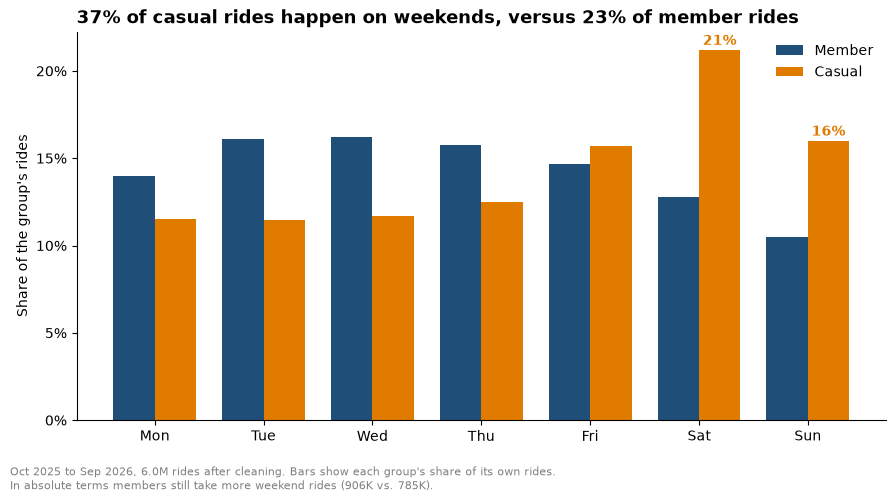

In [12]:
# Share of each group's rides by day of week, as bars; this cell also loads the data from rides_features.parquet

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

rides = pd.read_parquet("../data/clean/rides_features.parquet",
                        columns=["member_casual", "day_of_week", "hour", "day_type",
                                 "season", "ride_min", "rideable_type"])

COLORS = {"member": "#1f4e79", "casual": "#e07b00"}

dow = pd.crosstab(rides["day_of_week"], rides["member_casual"], normalize="columns") * 100
x = list(range(7))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar([i - w/2 for i in x], dow["member"], w, label="Member", color=COLORS["member"])
ax.bar([i + w/2 for i in x], dow["casual"], w, label="Casual", color=COLORS["casual"])
ax.set_xticks(x)
ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_yticks(range(0, 25, 5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Share of the group's rides")
ax.set_title("37% of casual rides happen on weekends, versus 23% of member rides",
             loc="left", fontsize=13, fontweight="bold")
for i in (5, 6):
    ax.text(i + w/2, dow["casual"].iloc[i] + 0.3, f"{dow['casual'].iloc[i]:.0f}%",
            ha="center", fontsize=10, color=COLORS["casual"], fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.text(0.01, 0.01,
         "Oct 2025 to Sep 2026, 6.0M rides after cleaning. Bars show each group's share of its own rides.\n"
         "In absolute terms members still take more weekend rides (906K vs. 785K).",
         fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.07, 1, 1])

plt.show()

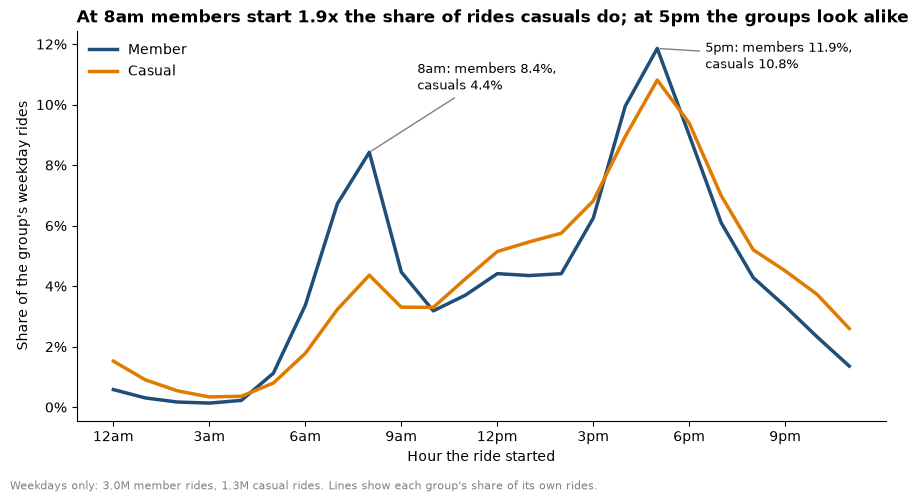

In [7]:
# Share of each group's weekday rides by hour the ride started

wk = rides[rides["day_type"] == "Weekday"]
hr = pd.crosstab(wk["hour"], wk["member_casual"], normalize="columns") * 100
n_wk = wk["member_casual"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(hr.index, hr["member"], color=COLORS["member"], lw=2.5, label="Member")
ax.plot(hr.index, hr["casual"], color=COLORS["casual"], lw=2.5, label="Casual")
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(["12am", "3am", "6am", "9am", "12pm", "3pm", "6pm", "9pm"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Share of the group's weekday rides")
ax.set_xlabel("Hour the ride started")

ax.annotate(f"8am: members {hr.loc[8, 'member']:.1f}%,\ncasuals {hr.loc[8, 'casual']:.1f}%",
            xy=(8, hr.loc[8, "member"]), xytext=(9.5, 10.5),
            arrowprops=dict(arrowstyle="-", color="gray"), fontsize=9)
ax.annotate(f"5pm: members {hr.loc[17, 'member']:.1f}%,\ncasuals {hr.loc[17, 'casual']:.1f}%",
            xy=(17, hr.loc[17, "member"]), xytext=(18.5, 11.2),
            arrowprops=dict(arrowstyle="-", color="gray"), fontsize=9)

ax.set_title(f"At 8am members start {hr.loc[8, 'member']/hr.loc[8, 'casual']:.1f}x the share of rides casuals do; "
             f"at 5pm the groups look alike",
             loc="left", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01,
         f"Weekdays only: {n_wk['member']/1e6:.1f}M member rides, {n_wk['casual']/1e6:.1f}M casual rides. "
         "Lines show each group's share of its own rides.",
         fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])

plt.show()

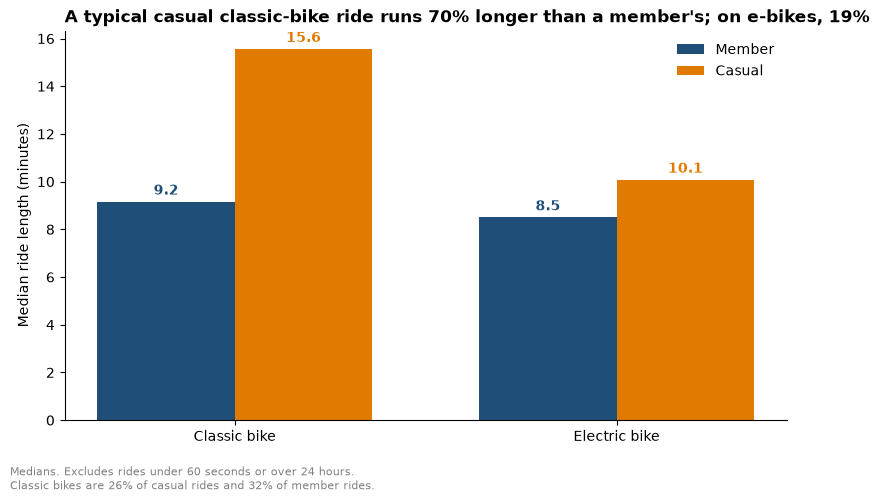

In [9]:
# Median ride length in minutes by bike type and rider group

med = (rides.groupby(["rideable_type", "member_casual"], observed=True)["ride_min"]
            .median().unstack().loc[["classic_bike", "electric_bike"]])
gap = (med["casual"] / med["member"] - 1) * 100
classic_share = rides.groupby("member_casual", observed=True)["rideable_type"] \
                     .apply(lambda s: (s == "classic_bike").mean() * 100)

fig, ax = plt.subplots(figsize=(8, 5))
x = [0, 1]
w = 0.36
ax.bar([i - w/2 for i in x], med["member"], w, label="Member", color=COLORS["member"])
ax.bar([i + w/2 for i in x], med["casual"], w, label="Casual", color=COLORS["casual"])
for i, bike in enumerate(med.index):
    ax.text(i - w/2, med.loc[bike, "member"] + 0.3, f"{med.loc[bike, 'member']:.1f}",
            ha="center", fontsize=10, color=COLORS["member"], fontweight="bold")
    ax.text(i + w/2, med.loc[bike, "casual"] + 0.3, f"{med.loc[bike, 'casual']:.1f}",
            ha="center", fontsize=10, color=COLORS["casual"], fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["Classic bike", "Electric bike"])
ax.set_ylabel("Median ride length (minutes)")
ax.set_title(f"A typical casual classic-bike ride runs {gap['classic_bike']:.0f}% longer than a member's; "
             f"on e-bikes, {gap['electric_bike']:.0f}%",
             loc="left", fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.text(0.01, 0.01,
         "Medians. Excludes rides under 60 seconds or over 24 hours.\n"
         f"Classic bikes are {classic_share['casual']:.0f}% of casual rides "
         f"and {classic_share['member']:.0f}% of member rides.",
         fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.07, 1, 1])

plt.show()

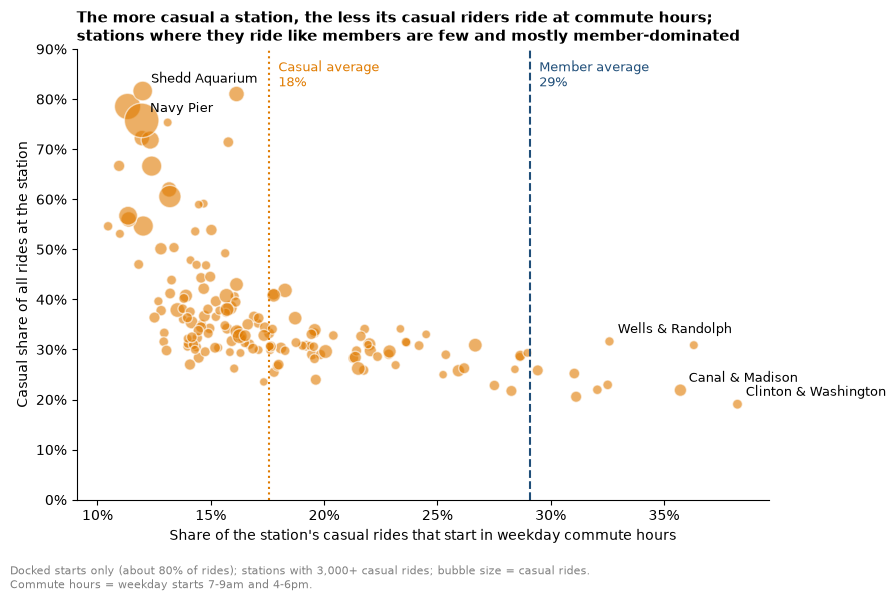

In [10]:
# One bubble per station: x = share of the station's casual rides that start in commute hours, y = casual share of all rides there, bubble size = casual rides

st = pd.read_parquet("../data/clean/rides_features.parquet",
                     columns=["start_station_name", "member_casual", "day_type", "hour"])
st = st.dropna(subset=["start_station_name"])
st["commute"] = (st["day_type"] == "Weekday") & st["hour"].isin([7, 8, 16, 17])

cas = st[st["member_casual"] == "casual"]
mem_base = st.loc[st["member_casual"] == "member", "commute"].mean() * 100
cas_base = cas["commute"].mean() * 100

by = cas.groupby("start_station_name", observed=True).agg(
    casual_rides=("commute", "size"), commute_share=("commute", "mean"))
tot = st.groupby("start_station_name", observed=True).size()
by["casual_share"] = by["casual_rides"] / tot.reindex(by.index) * 100
by["commute_share"] *= 100
big = by[by["casual_rides"] >= 3000]

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(big["commute_share"], big["casual_share"], s=big["casual_rides"] / 80,
           color=COLORS["casual"], alpha=0.6, edgecolor="white")
ax.axvline(mem_base, color=COLORS["member"], ls="--", lw=1.5)
ax.text(mem_base + 0.4, 88, f"Member average\n{mem_base:.0f}%", color=COLORS["member"], fontsize=9, va="top")
ax.axvline(cas_base, color=COLORS["casual"], ls=":", lw=1.5)
ax.text(cas_base + 0.4, 88, f"Casual average\n{cas_base:.0f}%", color=COLORS["casual"], fontsize=9, va="top")

labels = {"Navy Pier": "Navy Pier", "Shedd Aquarium": "Shedd Aquarium",
          "Clinton St & Washington Blvd 2": "Clinton & Washington",
          "Canal St & Madison St": "Canal & Madison",
          "Wells St & Randolph St": "Wells & Randolph"}
for name, short in labels.items():
    if name in big.index:
        ax.annotate(short, (big.loc[name, "commute_share"], big.loc[name, "casual_share"]),
                    xytext=(6, 6), textcoords="offset points", fontsize=9)

ax.set_xlabel("Share of the station's casual rides that start in weekday commute hours")
ax.set_ylabel("Casual share of all rides at the station")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 90)
ax.set_title("The more casual a station, the less its casual riders ride at commute hours;\n"
             "stations where they ride like members are few and mostly member-dominated",
             loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 1])
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01,
         "Docked starts only (about 80% of rides); stations with 3,000+ casual rides; bubble size = casual rides.\n"
         "Commute hours = weekday starts 7-9am and 4-6pm.",
         fontsize=8, color="gray")
plt.tight_layout(rect=[0, 0.06, 1, 1])

plt.show()

In [11]:
# Counts of docked casual rides, casual commute-hour rides, and the Member-like and Attraction stations; these are the figures behind Finding 4

member_like = big[big["commute_share"] >= mem_base]
attract = big[(big["commute_share"] < cas_base) & (big["casual_share"] >= 50)]
print("docked casual rides:", len(cas))
print("casual rides in weekday commute hours:", int(cas["commute"].sum()),
      f"({cas['commute'].mean()*100:.1f}%)")
print("member-like stations:", len(member_like), "| casual rides:", int(member_like["casual_rides"].sum()),
      f"({member_like['casual_rides'].sum()/len(cas)*100:.1f}% of docked casual rides)")
print("attraction stations:", len(attract), "| casual rides:", int(attract["casual_rides"].sum()),
      f"({attract['casual_rides'].sum()/len(cas)*100:.1f}% of docked casual rides)")

docked casual rides: 1678592
casual rides in weekday commute hours: 295136 (17.6%)
member-like stations: 9 | casual rides: 40090 (2.4% of docked casual rides)
attraction stations: 23 | casual rides: 263416 (15.7% of docked casual rides)
